In [2]:
# Retail Credit Risk & Predictive Default Scoring Engine

# Predicting Probability of Loan Default using Machine Learning

# Dataset: Home Credit Default Risk
# Models: Logistic Regression + XGBoost

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import os

DATA_PATH = "/content/drive/MyDrive/Credit_Risk_Project/data"

print(os.listdir(DATA_PATH))

['application_test.csv', 'application_train.csv', 'credit_card_balance.csv', 'POS_CASH_balance.csv', 'previous_application.csv', 'bureau.csv', 'bureau_balance.csv', 'HomeCredit_columns_description.csv', 'installments_payments.csv', 'sample_submission.csv']


In [8]:
import pandas as pd

df = pd.read_csv(f"{DATA_PATH}/application_train.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (307511, 122)


In [9]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
target_counts = df["TARGET"].value_counts()

print(target_counts)

TARGET
0    282686
1     24825
Name: count, dtype: int64


In [11]:
target_percentage = df["TARGET"].value_counts(normalize=True) * 100

print(target_percentage)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


In [12]:
print("Default rate:", df["TARGET"].mean() * 100, "%")

Default rate: 8.072881945686495 %


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [14]:
print("Numeric columns:", df.select_dtypes(include="number").shape[1])
print("Categorical columns:", df.select_dtypes(include="object").shape[1])

Numeric columns: 106
Categorical columns: 16


In [15]:
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df)) * 100
})

missing_summary = missing_summary.sort_values(
    "missing_percent",
    ascending=False
)

missing_summary.head(20)

,missing_count,missing_percent
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


In [16]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [17]:
print("Missing TARGET values:", df["TARGET"].isna().sum())

Missing TARGET values: 0


In [18]:
print("Unique SK_ID_CURR:", df["SK_ID_CURR"].nunique())
print("Total rows:", len(df))

Unique SK_ID_CURR: 307511
Total rows: 307511


In [19]:
unique_counts = df.nunique()

constant_columns = unique_counts[unique_counts <= 1]

print("Constant columns:")
print(constant_columns)

Constant columns:
Series([], dtype: int64)


In [20]:
pd.set_option("display.max_rows", 150)

print(df.columns.tolist())

['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELE

In [21]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,1.000020e+05,189145.500000,278202.000000,367142.500000,4.562550e+05
TARGET,307511.0,0.080729,0.272419,0.000000e+00,0.000000,0.000000,0.000000,1.000000e+00
CNT_CHILDREN,307511.0,0.417052,0.722121,0.000000e+00,0.000000,0.000000,1.000000,1.900000e+01
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,2.565000e+04,112500.000000,147150.000000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,4.500000e+04,270000.000000,513531.000000,808650.000000,4.050000e+06
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1.615500e+03,16524.000000,24903.000000,34596.000000,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,4.050000e+04,238500.000000,450000.000000,679500.000000,4.050000e+06
REGION_POPULATION_RELATIVE,307511.0,0.020868,0.013831,2.900000e-04,0.010006,0.018850,0.028663,7.250800e-02
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-2.522900e+04,-19682.000000,-15750.000000,-12413.000000,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-1.791200e+04,-2760.000000,-1213.000000,-289.000000,3.652430e+05


In [22]:
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [23]:
for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(10))


NAME_CONTRACT_TYPE
NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

CODE_GENDER
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

FLAG_OWN_CAR
FLAG_OWN_CAR
N    202924
Y    104587
Name: count, dtype: int64

FLAG_OWN_REALTY
FLAG_OWN_REALTY
Y    213312
N     94199
Name: count, dtype: int64

NAME_TYPE_SUITE
NAME_TYPE_SUITE
Unaccompanied      248526
Family              40149
Spouse, partner     11370
Children             3267
Other_B              1770
NaN                  1292
Other_A               866
Group of people       271
Name: count, dtype: int64

NAME_INCOME_TYPE
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

NAME_EDUCATION_TYPE
NAME_EDUCATION_TYPE
Secondary / s

In [24]:
check_columns = [
    "OCCUPATION_TYPE",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "COMMONAREA_AVG",
    "OWN_CAR_AGE"
]

for col in check_columns:
    missing_rate = df[col].isna().mean() * 100

    default_rate_missing = df.loc[
        df[col].isna(), "TARGET"
    ].mean() * 100

    default_rate_present = df.loc[
        df[col].notna(), "TARGET"
    ].mean() * 100

    print(f"\n{col}")
    print(f"Missing: {missing_rate:.2f}%")
    print(f"Default rate when missing: {default_rate_missing:.2f}%")
    print(f"Default rate when present: {default_rate_present:.2f}%")


OCCUPATION_TYPE
Missing: 31.35%
Default rate when missing: 6.51%
Default rate when present: 8.79%

EXT_SOURCE_1
Missing: 56.38%
Default rate when missing: 8.52%
Default rate when present: 7.50%

EXT_SOURCE_2
Missing: 0.21%
Default rate when missing: 7.88%
Default rate when present: 8.07%

EXT_SOURCE_3
Missing: 19.83%
Default rate when missing: 9.31%
Default rate when present: 7.77%

COMMONAREA_AVG
Missing: 69.87%
Default rate when missing: 8.57%
Default rate when present: 6.91%

OWN_CAR_AGE
Missing: 65.99%
Default rate when missing: 8.50%
Default rate when present: 7.24%


In [25]:
risk_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH",
    "EXT_SOURCE_2"
]

df[risk_features].describe().T

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,2.565000e+04,112500.000000,147150.000000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,4.500000e+04,270000.000000,513531.000000,808650.000000,4.050000e+06
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1.615500e+03,16524.000000,24903.000000,34596.000000,2.580255e+05
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-2.522900e+04,-19682.000000,-15750.000000,-12413.000000,-7.489000e+03
EXT_SOURCE_2,306851.0,0.514393,0.191060,8.173617e-08,0.392457,0.565961,0.663617,8.549997e-01


In [26]:
df["INCOME_GROUP"] = pd.qcut(
    df["AMT_INCOME_TOTAL"],
    q=5,
    duplicates="drop"
)

income_risk = df.groupby(
    "INCOME_GROUP",
    observed=True
)["TARGET"].agg(["count", "mean"])

income_risk["default_rate_%"] = income_risk["mean"] * 100

income_risk

,count,mean,default_rate_%
INCOME_GROUP,,,
"(25649.999, 99000.0]",63671,0.082062,8.206248
"(99000.0, 135000.0]",85756,0.085883,8.588320
"(135000.0, 162000.0]",35453,0.086847,8.684738
"(162000.0, 225000.0]",75513,0.080569,8.056891
"(225000.0, 117000000.0]",47118,0.065198,6.519801


In [27]:
df["CREDIT_INCOME_RATIO"] = (
    df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
)

df["CREDIT_INCOME_RATIO"].describe()

,CREDIT_INCOME_RATIO
count,307511.000000
mean,3.957570
std,2.689728
min,0.004808
25%,2.018667
50%,3.265067
75%,5.159880
max,84.736842


In [28]:
df["ANNUITY_INCOME_RATIO"] = (
    df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
)

df["ANNUITY_INCOME_RATIO"].describe()

,ANNUITY_INCOME_RATIO
count,307499.000000
mean,0.180930
std,0.094574
min,0.000224
25%,0.114782
50%,0.162833
75%,0.229067
max,1.875965


In [29]:
df["AGE_YEARS"] = (
    -df["DAYS_BIRTH"] / 365.25
)

df["AGE_YEARS"].describe()

,AGE_YEARS
count,307511.000000
mean,43.906900
std,11.947950
min,20.503765
25%,33.984942
50%,43.121150
75%,53.886379
max,69.073238


In [30]:
df["CREDIT_INCOME_GROUP"] = pd.qcut(
    df["CREDIT_INCOME_RATIO"],
    q=5,
    duplicates="drop"
)

credit_income_risk = df.groupby(
    "CREDIT_INCOME_GROUP",
    observed=True
)["TARGET"].agg(["count", "mean"])

credit_income_risk["default_rate_%"] = (
    credit_income_risk["mean"] * 100
)

credit_income_risk

,count,mean,default_rate_%
CREDIT_INCOME_GROUP,,,
"(0.00381, 1.818]",61539,0.073352,7.335186
"(1.818, 2.764]",61502,0.085672,8.567201
"(2.764, 3.906]",61466,0.089253,8.925259
"(3.906, 5.769]",61505,0.082839,8.283879
"(5.769, 84.737]",61499,0.072538,7.253776


In [31]:
df["ANNUITY_INCOME_GROUP"] = pd.qcut(
    df["ANNUITY_INCOME_RATIO"],
    q=5,
    duplicates="drop"
)

annuity_income_risk = df.groupby(
    "ANNUITY_INCOME_GROUP",
    observed=True
)["TARGET"].agg(["count", "mean"])

annuity_income_risk["default_rate_%"] = (
    annuity_income_risk["mean"] * 100
)

annuity_income_risk

,count,mean,default_rate_%
ANNUITY_INCOME_GROUP,,,
"(-0.000776, 0.104]",61500,0.071967,7.196748
"(0.104, 0.144]",61507,0.078316,7.831629
"(0.144, 0.186]",61494,0.081260,8.125996
"(0.186, 0.247]",61522,0.086961,8.696076
"(0.247, 1.876]",61476,0.085155,8.515518


In [32]:
df["AGE_GROUP"] = pd.qcut(
    df["AGE_YEARS"],
    q=5,
    duplicates="drop"
)

age_risk = df.groupby(
    "AGE_GROUP",
    observed=True
)["TARGET"].agg(["count", "mean"])

age_risk["default_rate_%"] = (
    age_risk["mean"] * 100
)

age_risk

,count,mean,default_rate_%
AGE_GROUP,,,
"(20.503, 32.016]",61512,0.112824,11.282351
"(32.016, 39.469]",61504,0.093295,9.329475
"(39.469, 47.146]",61509,0.078493,7.849258
"(47.146, 56.055]",61491,0.067392,6.739198
"(56.055, 69.073]",61495,0.051630,5.163021


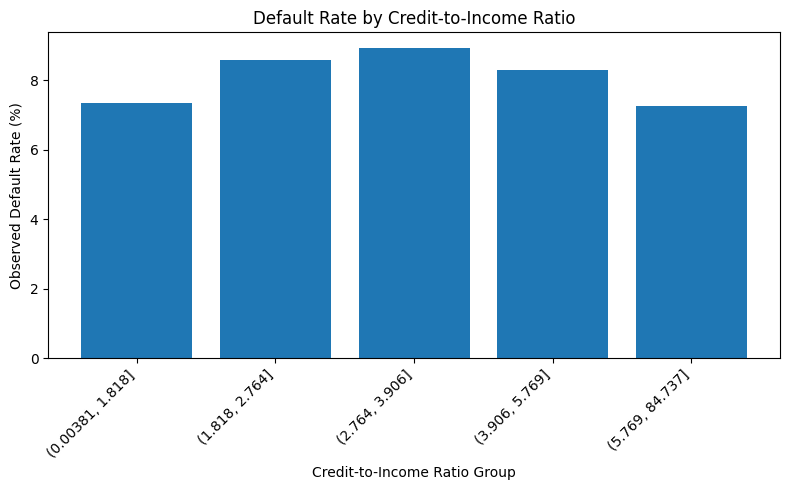

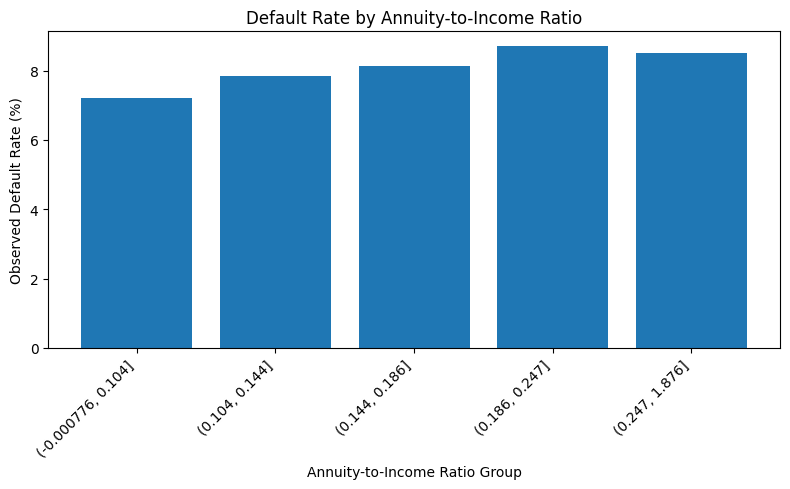

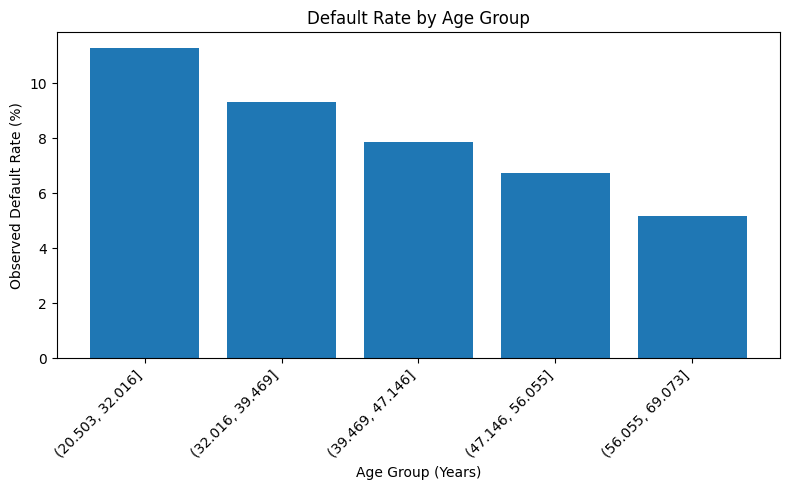

In [33]:
import matplotlib.pyplot as plt

# 1. Credit-to-Income Ratio
plt.figure(figsize=(8, 5))
plt.bar(
    credit_income_risk.index.astype(str),
    credit_income_risk["default_rate_%"]
)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Credit-to-Income Ratio Group")
plt.ylabel("Observed Default Rate (%)")
plt.title("Default Rate by Credit-to-Income Ratio")
plt.tight_layout()
plt.show()


# 2. Annuity-to-Income Ratio
plt.figure(figsize=(8, 5))
plt.bar(
    annuity_income_risk.index.astype(str),
    annuity_income_risk["default_rate_%"]
)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Annuity-to-Income Ratio Group")
plt.ylabel("Observed Default Rate (%)")
plt.title("Default Rate by Annuity-to-Income Ratio")
plt.tight_layout()
plt.show()


# 3. Age
plt.figure(figsize=(8, 5))
plt.bar(
    age_risk.index.astype(str),
    age_risk["default_rate_%"]
)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Age Group (Years)")
plt.ylabel("Observed Default Rate (%)")
plt.title("Default Rate by Age Group")
plt.tight_layout()
plt.show()

In [34]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Remove EDA-only columns
eda_columns = [
    "CREDIT_INCOME_GROUP",
    "ANNUITY_INCOME_GROUP",
    "AGE_GROUP"
]

df_model = df.drop(columns=eda_columns, errors="ignore").copy()


# Target and ID

X = df_model.drop(columns=["TARGET", "SK_ID_CURR"])
y = df_model["TARGET"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nDefault distribution:")
print(y.value_counts())
print("\nDefault rate:", round(y.mean() * 100, 2), "%")



numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("\nTrain:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Feature matrix shape: (307511, 124)
Target shape: (307511,)

Default distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Default rate: 8.07 %

Numeric features: 107
Categorical features: 16

Train: (215257, 124)
Validation: (46127, 124)
Test: (46127, 124)


In [35]:


from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Numeric pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [36]:

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ))
])

print("Training Logistic Regression...")

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained.")

Training Logistic Regression...
Logistic Regression trained.


In [37]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Scale positive weight:", round(scale_pos_weight, 2))

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="auc",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training XGBoost...")

xgb_model.fit(X_train, y_train)

print("XGBoost trained.")

Scale positive weight: 11.39
Training XGBoost...
XGBoost trained.


In [38]:
# MODEL EVALUATION
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_curve
)

def calculate_ks(y_true, y_prob):
    """
    Calculate KS statistic from cumulative distributions.
    """
    temp = pd.DataFrame({
        "actual": y_true.values,
        "probability": y_prob
    })

    temp = temp.sort_values(
        "probability",
        ascending=False
    ).reset_index(drop=True)

    total_bad = temp["actual"].sum()
    total_good = len(temp) - total_bad

    temp["cum_bad"] = temp["actual"].cumsum() / total_bad
    temp["cum_good"] = (
        (1 - temp["actual"]).cumsum() / total_good
    )

    temp["ks"] = (
        temp["cum_bad"] -
        temp["cum_good"]
    )

    return temp["ks"].abs().max()


def evaluate_model(name, model):

    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.50).astype(int)

    auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    ks = calculate_ks(y_test, y_prob)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    cm = confusion_matrix(y_test, y_pred)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(f"ROC-AUC : {auc:.4f}")
    print(f"PR-AUC  : {pr_auc:.4f}")
    print(f"KS      : {ks:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")

    print("\nConfusion Matrix:")
    print(cm)

    return {
        "model": name,
        "roc_auc": auc,
        "pr_auc": pr_auc,
        "ks": ks,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


logistic_results = evaluate_model(
    "Logistic Regression",
    logistic_model
)

xgb_results = evaluate_model(
    "XGBoost",
    xgb_model
)

results_df = pd.DataFrame([
    logistic_results,
    xgb_results
])

print("\nMODEL COMPARISON")
display(results_df)


Logistic Regression
ROC-AUC : 0.7485
PR-AUC  : 0.2200
KS      : 0.3777
Precision: 0.1626
Recall   : 0.6869
F1 Score : 0.2629

Confusion Matrix:
[[29226 13177]
 [ 1166  2558]]

XGBoost
ROC-AUC : 0.7610
PR-AUC  : 0.2446
KS      : 0.3932
Precision: 0.1721
Recall   : 0.6697
F1 Score : 0.2738

Confusion Matrix:
[[30406 11997]
 [ 1230  2494]]

MODEL COMPARISON


,model,roc_auc,pr_auc,ks,precision,recall,f1
0,Logistic Regression,0.748516,0.220019,0.377720,0.162568,0.686896,0.262912
1,XGBoost,0.760978,0.244642,0.393184,0.172107,0.669710,0.273840


In [44]:

# THRESHOLD ANALYSIS


from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Get validation probabilities
xgb_val_prob = xgb_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.10, 0.51, 0.05)

threshold_results = []

for threshold in thresholds:

    y_val_pred = (xgb_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_val_pred
    ).ravel()

    precision = precision_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positives": fp,
        "false_negatives": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,threshold,precision,recall,f1,false_positives,false_negatives
0,0.10,0.083388,0.996241,0.153894,40781,14
1,0.15,0.088173,0.984962,0.161857,37932,56
2,0.20,0.095217,0.965360,0.173337,34161,129
3,0.25,0.104231,0.937970,0.187614,30019,231
4,0.30,0.114645,0.901182,0.203412,25917,368
5,0.35,0.126422,0.853383,0.220220,21960,546
6,0.40,0.138930,0.798067,0.236662,18420,752
7,0.45,0.152658,0.729592,0.252486,15081,1007
8,0.50,0.169196,0.661654,0.269481,12099,1260


In [40]:
# Find threshold with highest validation F1

best_threshold_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

best_threshold = best_threshold_row["threshold"]

print(
    "Selected threshold:",
    round(best_threshold, 2)
)

print(
    "Validation F1:",
    round(best_threshold_row["f1"], 4)
)

print(
    "Validation Precision:",
    round(best_threshold_row["precision"], 4)
)

print(
    "Validation Recall:",
    round(best_threshold_row["recall"], 4)
)

Selected threshold: 0.5
Validation F1: 0.2695
Validation Precision: 0.1692
Validation Recall: 0.6617


In [41]:

xgb_test_prob = xgb_model.predict_proba(X_test)[:, 1]

xgb_test_pred = (
    xgb_test_prob >= best_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    xgb_test_pred
).ravel()

final_precision = precision_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

print("=" * 60)
print("FINAL XGBOOST TEST PERFORMANCE")
print("=" * 60)

print(f"Threshold : {best_threshold:.2f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1 Score  : {final_f1:.4f}")

print("\nConfusion Matrix:")
print(
    pd.DataFrame(
        [[tn, fp], [fn, tp]],
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )
)

FINAL XGBOOST TEST PERFORMANCE
Threshold : 0.50
Precision : 0.1721
Recall    : 0.6697
F1 Score  : 0.2738

Confusion Matrix:
          Predicted 0  Predicted 1
Actual 0        30406        11997
Actual 1         1230         2494


In [42]:

# PREDICTIVE RISK SCORING

risk_output = X_test.copy()

risk_output["SK_ID_CURR"] = df.loc[
    X_test.index,
    "SK_ID_CURR"
]

risk_output["ACTUAL_DEFAULT"] = y_test.values

risk_output["PD"] = xgb_test_prob

# Convert PD into an intuitive 0–100 risk score
risk_output["RISK_SCORE"] = (
    risk_output["PD"] * 100
).round(2)

# Risk bands
risk_output["RISK_BAND"] = pd.cut(
    risk_output["PD"],
    bins=[-np.inf, 0.05, 0.10, 0.20, np.inf],
    labels=[
        "Low Risk",
        "Moderate Risk",
        "High Risk",
        "Very High Risk"
    ]
)

risk_output[
    [
        "SK_ID_CURR",
        "ACTUAL_DEFAULT",
        "PD",
        "RISK_SCORE",
        "RISK_BAND"
    ]
].head(10)

,SK_ID_CURR,ACTUAL_DEFAULT,PD,RISK_SCORE,RISK_BAND
17424,120321,0,0.515364,51.540001,Very High Risk
305296,453712,1,0.287790,28.780001,Very High Risk
17224,120090,0,0.219049,21.900000,Very High Risk
215169,349328,0,0.361057,36.110001,Very High Risk
181299,310116,0,0.334297,33.430000,Very High Risk
111863,229777,0,0.566920,56.689999,Very High Risk
200249,332138,1,0.869128,86.910004,Very High Risk
181066,309839,0,0.116710,11.670000,High Risk
99013,214962,1,0.587602,58.759998,Very High Risk
18390,121452,0,0.714638,71.459999,Very High Risk


In [43]:

risk_band_summary = (
    risk_output
    .groupby("RISK_BAND", observed=True)
    .agg(
        borrowers=("SK_ID_CURR", "count"),
        average_pd=("PD", "mean"),
        observed_default_rate=("ACTUAL_DEFAULT", "mean")
    )
)

risk_band_summary["average_pd_%"] = (
    risk_band_summary["average_pd"] * 100
)

risk_band_summary["observed_default_rate_%"] = (
    risk_band_summary["observed_default_rate"] * 100
)

display(
    risk_band_summary[
        [
            "borrowers",
            "average_pd_%",
            "observed_default_rate_%"
        ]
    ]
)

,borrowers,average_pd_%,observed_default_rate_%
RISK_BAND,,,
Low Risk,209,3.864215,0.478469
Moderate Risk,1448,7.999419,1.450276
High Risk,6916,15.440956,1.633892
Very High Risk,37554,46.024818,9.556905


In [45]:

# XGBOOST FEATURE IMPORTANCE
# Get transformed feature names
feature_names = xgb_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get trained XGBoost classifier
xgb_classifier = xgb_model.named_steps[
    "classifier"
]

importance_values = xgb_classifier.feature_importances_

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importance_values
})

feature_importance = (
    feature_importance
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 20 features:")
display(feature_importance.head(20))

Top 20 features:


,feature,importance
0,num__EXT_SOURCE_2,0.036827
1,num__EXT_SOURCE_3,0.036481
2,cat__NAME_EDUCATION_TYPE_Higher education,0.022953
3,cat__CODE_GENDER_F,0.016656
4,cat__CODE_GENDER_M,0.014483
5,num__FLAG_DOCUMENT_3,0.014354
6,cat__NAME_INCOME_TYPE_Pensioner,0.013298
7,num__EXT_SOURCE_1,0.012636
8,cat__FLAG_OWN_CAR_Y,0.011704
9,cat__NAME_CONTRACT_TYPE_Revolving loans,0.011469


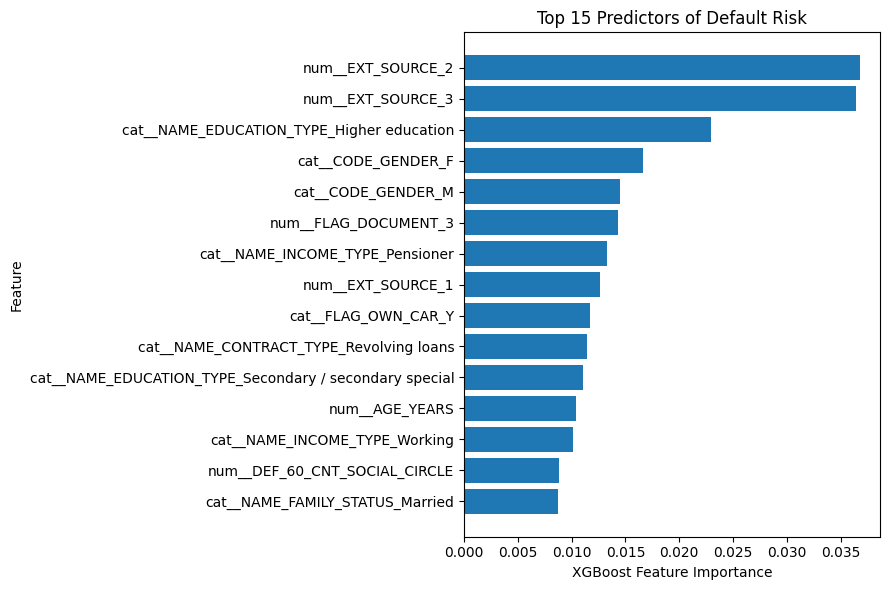

In [46]:
# Top 15 feature importance

top_features = feature_importance.head(15).sort_values(
    "importance"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("XGBoost Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Predictors of Default Risk")

plt.tight_layout()
plt.show()

In [47]:
# SAVE RESULTS

import os

PROJECT_PATH = "/content/drive/MyDrive/Credit_Risk_Project"

os.makedirs(f"{PROJECT_PATH}/results", exist_ok=True)

# Model comparison
results_df.to_csv(
    f"{PROJECT_PATH}/results/model_comparison.csv",
    index=False
)

# Threshold analysis
threshold_df.to_csv(
    f"{PROJECT_PATH}/results/threshold_analysis.csv",
    index=False
)

# Feature importance
feature_importance.to_csv(
    f"{PROJECT_PATH}/results/feature_importance.csv",
    index=False
)

# Risk output
risk_output[
    [
        "SK_ID_CURR",
        "ACTUAL_DEFAULT",
        "PD",
        "RISK_SCORE",
        "RISK_BAND"
    ]
].to_csv(
    f"{PROJECT_PATH}/results/risk_predictions.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.
